# Resultados de clasificación

In [1]:
import sys, json, pickle, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from myst_nb import glue
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix
from src import estilo
from src.estilo import RIO, SED, CAU, ALE, NEU, COLORES
from src.config import RESULTADOS
from src.analysis import tabla_pliegues, resumen, nombres, oof
from src.models import NOMBRES_MODELO, NOMBRES_BALANCEO, NOMBRES_OPT
from src.evaluation import ece, diagrama_confiabilidad, Recalibrador
from src.experiment import cargar_datos
D = cargar_datos()
pl = tabla_pliegues("clf_calamar")
met = ["pr_auc", "roc_auc", "f1", "precision", "recall", "accuracy", "brier"]
res = nombres(resumen(pl, met))
mejores = pd.read_csv(RESULTADOS / "mejores_clf.csv")
fin = {r["modelo"]: r for r in pickle.load(open(RESULTADOS / "final_clf.pkl", "rb"))}
glue("n_combos", len(res), display=False)
glue("n_tareas", len(pl), display=False)

## Tabla maestra

Las {glue:text}`n_combos` combinaciones se evaluaron en los doce bloques externos
({glue:text}`n_tareas` optimizaciones). La tabla muestra las veinte mejores según la PR-AUC
media del bucle externo; la tabla completa, con los hiperparámetros de cada pliegue, el tiempo
y la semilla, está en `results/tabla_maestra.csv` (capítulo 9).

In [2]:
fmt = lambda m, s: f"{m:.3f} ± {s:.3f}"
vista = res.sort_values("pr_auc_mean", ascending=False).head(20)
pd.DataFrame({"Modelo": vista.nombre, "Balanceo": vista.balanceo_nombre, "Optimizador": vista.optimizador_nombre,
              "PR-AUC": [fmt(a, b) for a, b in zip(vista.pr_auc_mean, vista.pr_auc_std)],
              "ROC-AUC": [fmt(a, b) for a, b in zip(vista.roc_auc_mean, vista.roc_auc_std)],
              "F1": [fmt(a, b) for a, b in zip(vista.f1_mean, vista.f1_std)],
              "Recall": [fmt(a, b) for a, b in zip(vista.recall_mean, vista.recall_std)],
              "Brier": [fmt(a, b) for a, b in zip(vista.brier_mean, vista.brier_std)],
              "Tiempo total (s)": vista.t_total.round(0)}).reset_index(drop=True)

,Modelo,Balanceo,Optimizador,PR-AUC,ROC-AUC,F1,Recall,Brier,Tiempo total (s)
0,Random Forest,class_weight,Random,0.910 ± 0.075,0.974 ± 0.014,0.817 ± 0.127,0.917 ± 0.042,0.057 ± 0.021,1851.0
1,Random Forest,SMOTE,Grid,0.908 ± 0.095,0.974 ± 0.018,0.830 ± 0.123,0.918 ± 0.050,0.056 ± 0.020,3741.0
2,Random Forest,Sin balanceo,Grid,0.907 ± 0.106,0.973 ± 0.022,0.825 ± 0.118,0.849 ± 0.096,0.052 ± 0.017,2018.0
3,Random Forest,Sin balanceo,Bayesiana (TPE),0.907 ± 0.100,0.973 ± 0.020,0.827 ± 0.106,0.849 ± 0.082,0.052 ± 0.017,1462.0
4,Random Forest,Sin balanceo,Genética (DEAP),0.907 ± 0.097,0.973 ± 0.019,0.825 ± 0.109,0.844 ± 0.087,0.052 ± 0.017,2427.0
5,Random Forest,class_weight,Grid,0.906 ± 0.099,0.974 ± 0.018,0.832 ± 0.094,0.852 ± 0.068,0.052 ± 0.017,1926.0
6,Random Forest,class_weight,Bayesiana (TPE),0.906 ± 0.088,0.973 ± 0.016,0.820 ± 0.114,0.919 ± 0.056,0.058 ± 0.018,2101.0
7,Random Forest,SMOTE,Random,0.906 ± 0.092,0.974 ± 0.017,0.821 ± 0.125,0.931 ± 0.048,0.059 ± 0.021,3537.0
8,Random Forest,Sin balanceo,Random,0.906 ± 0.096,0.973 ± 0.019,0.826 ± 0.109,0.846 ± 0.086,0.052 ± 0.017,1943.0
9,Random Forest,SMOTE,Genética (DEAP),0.906 ± 0.092,0.973 ± 0.017,0.821 ± 0.126,0.924 ± 0.051,0.058 ± 0.021,4448.0


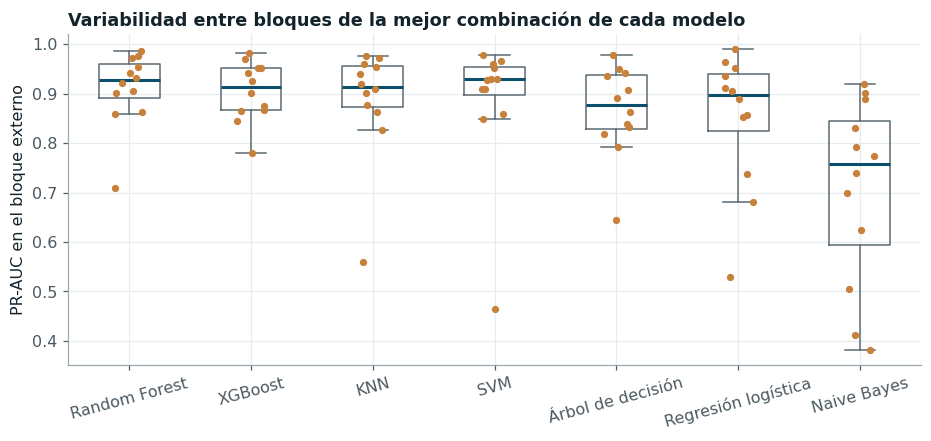

In [3]:
orden = mejores.sort_values("pr_auc_mean", ascending=False).modelo.tolist()
fig, ax = plt.subplots(figsize=(10, 3.9))
datos_caja = []
for i, m in enumerate(orden):
    f = mejores.set_index("modelo").loc[m]
    v = pl[(pl.modelo == m) & (pl.balanceo == f.balanceo) & (pl.optimizador == f.optimizador)].sort_values("pliegue")
    datos_caja.append(v.pr_auc.values)
    ax.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-.12, .12, len(v)), v.pr_auc, s=14, color=SED, zorder=3)
ax.boxplot(datos_caja, positions=range(len(orden)), widths=.5, showfliers=False,
           medianprops=dict(color=RIO, lw=2), boxprops=dict(color=NEU), whiskerprops=dict(color=NEU), capprops=dict(color=NEU))
ax.set_xticks(range(len(orden)), [NOMBRES_MODELO[m] for m in orden], rotation=15)
ax.set_ylabel("PR-AUC en el bloque externo"); ax.set_title("Variabilidad entre bloques de la mejor combinación de cada modelo")
plt.show()
mej = mejores.sort_values("pr_auc_mean", ascending=False)
glue("mejor_modelo", NOMBRES_MODELO[mej.iloc[0].modelo], display=False)
glue("mejor_pr", float(mej.iloc[0].pr_auc_mean), display=False)
glue("mejor_pr_sd", float(mej.iloc[0].pr_auc_std), display=False)
glue("peor_modelo", NOMBRES_MODELO[mej.iloc[-1].modelo], display=False)
glue("peor_pr", float(mej.iloc[-1].pr_auc_mean), display=False)
peor_bloque = pl.groupby("bloque").pr_auc.mean().idxmin()
glue("peor_bloque", peor_bloque, display=False)
glue("peor_bloque_pr", float(pl.groupby("bloque").pr_auc.mean().min()), display=False)

La mejor combinación es {glue:text}`mejor_modelo` con ponderación por clase y búsqueda
aleatoria, con una PR-AUC externa de {glue:text}`mejor_pr:.3f` ± {glue:text}`mejor_pr_sd:.3f`, y
las diez primeras posiciones de la tabla maestra son variantes de Random Forest separadas por
menos de una centésima. XGBoost aparece como el segundo algoritmo, con la combinación ADASYN y
búsqueda aleatoria, y su desviación entre bloques es la menor de las mejores combinaciones. En el
otro extremo, {glue:text}`peor_modelo` ({glue:text}`peor_pr:.3f`) paga el supuesto de
independencia condicional entre predictores que son, en buena parte, rezagos casi idénticos de la
misma serie.

La {numref}`fig-cajas-modelos` muestra que la variabilidad entre bloques supera con amplitud la
diferencia entre los mejores modelos. El bloque {glue:text}`peor_bloque` es el más difícil para
todos (PR-AUC media de {glue:text}`peor_bloque_pr:.2f` entre las 112 combinaciones): coincide con
el ascenso hacia la crecida de 2008, uno de los máximos anuales del registro, y con la transición
hacia La Niña de 2010-2011, de modo que el río atraviesa la banda en ascensos rápidos que el
estado actual anticipa mal. Esa dispersión es la razón de que las conclusiones de este capítulo
se apoyen en pruebas sobre bloques pareados y no en las medias.

## Efecto del balanceo de clases

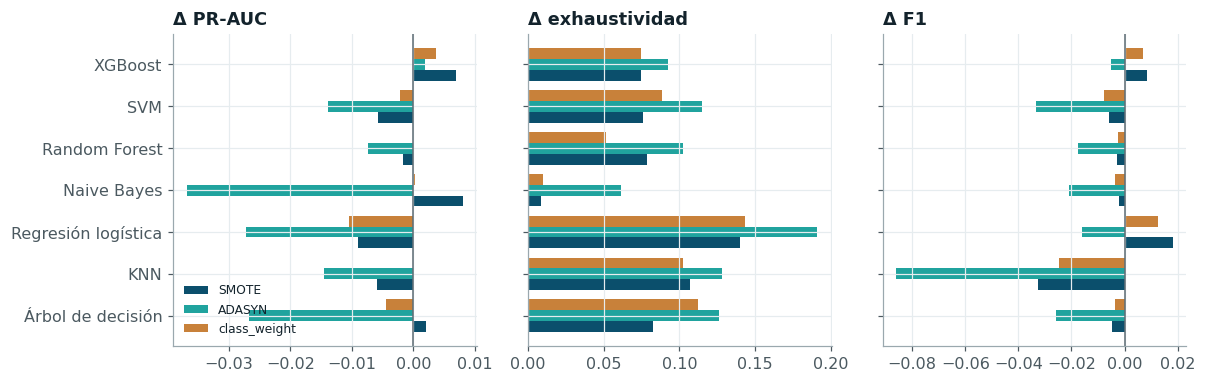

In [4]:
base = pl[pl.balanceo == "ninguno"].set_index(["modelo", "optimizador", "pliegue"])
filas = []
for b in ("smote", "adasyn", "balanced"):
    otro = pl[pl.balanceo == b].set_index(["modelo", "optimizador", "pliegue"])
    dif = (otro[["pr_auc", "recall", "f1", "precision", "brier"]] - base[["pr_auc", "recall", "f1", "precision", "brier"]]).reset_index()
    dif["balanceo"] = b
    filas.append(dif)
dif = pd.concat(filas)
fig, axs = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, metr, tit in zip(axs, ("pr_auc", "recall", "f1"), ("Δ PR-AUC", "Δ exhaustividad", "Δ F1")):
    t = dif.groupby(["modelo", "balanceo"])[metr].mean().unstack()
    t.index = [NOMBRES_MODELO[m] for m in t.index]
    t = t[["smote", "adasyn", "balanced"]]
    y = np.arange(len(t))
    for j, (b, col) in enumerate(zip(t.columns, (RIO, CAU, SED))):
        ax.barh(y + (j - 1) * .26, t[b], height=.26, color=col, label=NOMBRES_BALANCEO[b])
    ax.axvline(0, color=NEU, lw=1); ax.set_title(tit); ax.set_yticks(y, t.index)
axs[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()
from scipy.stats import wilcoxon
from src.stats_tests import holm
tab_b = []
for b in ("smote", "adasyn", "balanced"):
    g = dif[dif.balanceo == b]
    for metr in ("pr_auc", "recall", "f1"):
        tab_b.append({"balanceo": NOMBRES_BALANCEO[b], "métrica": metr, "Δ media": g[metr].mean(),
                      "fracción de mejoras": (g[metr] > 0).mean(), "p (Wilcoxon)": wilcoxon(g[metr]).pvalue})
tab_b = pd.DataFrame(tab_b)
tab_b["p (Holm)"] = holm(tab_b["p (Wilcoxon)"].values)
for b in ("SMOTE", "ADASYN", "class_weight"):
    for metr in ("pr_auc", "recall"):
        glue(f"bal_{b}_{metr}", float(tab_b[(tab_b.balanceo == b) & (tab_b["métrica"] == metr)]["Δ media"].iloc[0]), display=False)

In [5]:
tab_b.round(4)

,balanceo,métrica,Δ media,fracción de mejoras,p (Wilcoxon),p (Holm)
0,SMOTE,pr_auc,-0.0008,0.5179,0.5315,1.0000
1,SMOTE,recall,0.0811,0.9286,0.0000,0.0000
2,SMOTE,f1,-0.0031,0.4881,0.7202,1.0000
3,ADASYN,pr_auc,-0.0178,0.2976,0.0000,0.0000
4,ADASYN,recall,0.1167,0.9702,0.0000,0.0000
5,ADASYN,f1,-0.0293,0.3512,0.0000,0.0000
6,class_weight,pr_auc,-0.0019,0.3601,0.0084,0.0337
7,class_weight,recall,0.0833,0.9256,0.0000,0.0000
8,class_weight,f1,-0.0033,0.4613,0.2328,0.6983


El balanceo no mejora la discriminación. La PR-AUC, que evalúa el orden de los puntajes y no
depende del umbral, apenas cambia con SMOTE ({glue:text}`bal_SMOTE_pr_auc:+.4f`, no
significativo) o con la ponderación por clase ({glue:text}`bal_class_weight_pr_auc:+.4f`), y
empeora con ADASYN ({glue:text}`bal_ADASYN_pr_auc:+.4f`, significativo tras Holm). Lo que sí
cambia es el punto de operación con el umbral de 0,5: la exhaustividad sube entre
{glue:text}`bal_SMOTE_recall:.2f` y {glue:text}`bal_ADASYN_recall:.2f` puntos a costa de la
precisión, y el F1 queda igual o baja. La lectura es la esperada para un desbalance moderado (26 %
de positivos): las tres técnicas desplazan el umbral efectivo hacia la clase minoritaria, lo
que equivale a cambiar el costo relativo de los errores, pero no aportan información nueva sobre
qué días están en la banda. ADASYN resulta perjudicial porque concentra los sintéticos cerca de la
frontera, justamente donde la autocorrelación hace que los vecinos de un día positivo sean sus
propios días contiguos, de modo que interpola casi duplicados de los casos más ambiguos.

## Desempeño en la prueba reservada

Con la combinación ganadora de cada modelo se repitió la optimización sobre todo el
entrenamiento (1947-2009), se reentrenó el pipeline y se evaluó una única vez en 2010-2026.

In [6]:
y = D.y_clf_test.values
filas = []
for m in orden:
    r = fin[m]
    mt = r["metricas_test"]
    filas.append({"Modelo": NOMBRES_MODELO[m], "Balanceo": NOMBRES_BALANCEO[r["balanceo"]], "Optimizador": NOMBRES_OPT[r["optimizador"]],
                  "Accuracy": mt["accuracy"], "Precision": mt["precision"], "Recall": mt["recall"], "F1": mt["f1"],
                  "ROC-AUC": mt["roc_auc"], "PR-AUC": mt["pr_auc"], "Brier": mt["brier"],
                  "Inferencia (ms/fila)": r["t_inf_ms_fila"]})
tabla_test = pd.DataFrame(filas)
glue("test_mejor_pr", float(tabla_test["PR-AUC"].max()), display=False)
glue("test_mejor_modelo", tabla_test.loc[tabla_test["PR-AUC"].idxmax(), "Modelo"], display=False)
tabla_test.round(4)

,Modelo,Balanceo,Optimizador,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier,Inferencia (ms/fila)
0,Random Forest,class_weight,Random,0.9391,0.8575,0.9101,0.8830,0.9806,0.9495,0.0486,0.0056
1,XGBoost,ADASYN,Random,0.9152,0.7720,0.9427,0.8488,0.9797,0.9411,0.0584,0.0039
2,KNN,class_weight,Genética (DEAP),0.8967,0.7241,0.9547,0.8236,0.9769,0.9377,0.0695,0.4250
3,SVM,Sin balanceo,Random,0.9347,0.8712,0.8701,0.8707,0.9801,0.9496,0.0806,0.0273
4,Árbol de decisión,SMOTE,Grid,0.8831,0.7067,0.9181,0.7986,0.9604,0.8959,0.0762,0.0011
5,Regresión logística,Sin balanceo,Random,0.9083,0.8080,0.8354,0.8215,0.9665,0.8910,0.0642,0.0012
6,Naive Bayes,SMOTE,Genética (DEAP),0.7987,0.5646,0.8847,0.6893,0.9118,0.7553,0.1938,0.0024


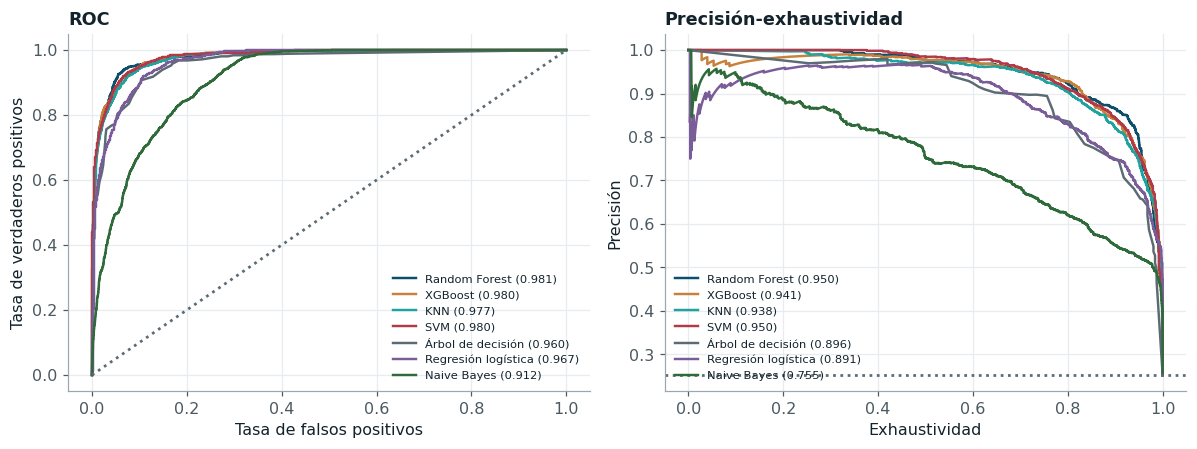

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for i, m in enumerate(orden):
    s = fin[m]["pred_test"]
    fpr, tpr, _ = roc_curve(y, s); pr_, rc_, _ = precision_recall_curve(y, s)
    c = (COLORES + ["#7a5c99", "#2f6b3a"])[i]
    axs[0].plot(fpr, tpr, color=c, lw=1.6, label=f"{NOMBRES_MODELO[m]} ({fin[m]['metricas_test']['roc_auc']:.3f})")
    axs[1].plot(rc_, pr_, color=c, lw=1.6, label=f"{NOMBRES_MODELO[m]} ({fin[m]['metricas_test']['pr_auc']:.3f})")
axs[0].plot([0, 1], [0, 1], ":", color=NEU); axs[1].axhline(y.mean(), ls=":", color=NEU)
axs[0].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="ROC")
axs[1].set(xlabel="Exhaustividad", ylabel="Precisión", title="Precisión-exhaustividad")
axs[0].legend(fontsize=7.5, loc="lower right"); axs[1].legend(fontsize=7.5, loc="lower left")
plt.tight_layout(); plt.show()

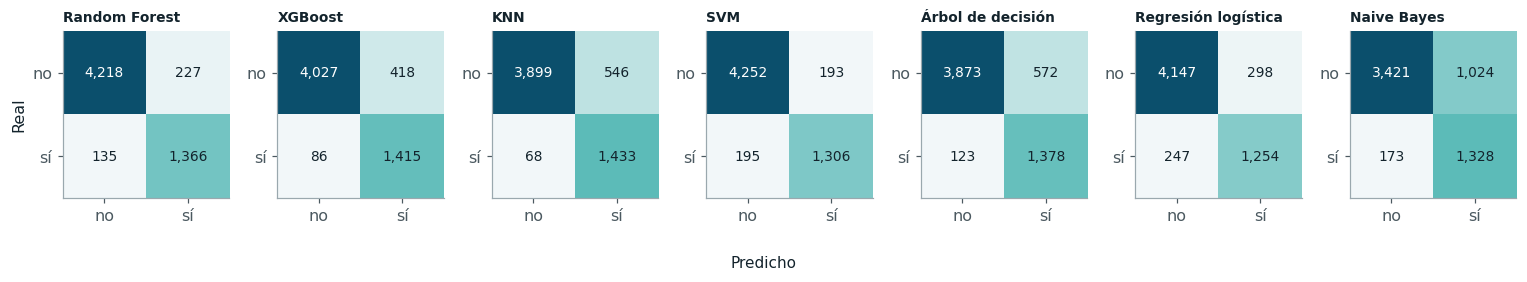

In [8]:
fig, axs = plt.subplots(1, len(orden), figsize=(14, 2.6))
for ax, m in zip(axs, orden):
    cm = confusion_matrix(y, (fin[m]["pred_test"] >= .5).astype(int))
    ax.imshow(cm, cmap=estilo.mapa_seq()); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=9, color="white" if cm[i, j] > cm.max() / 2 else "#13232c")
    ax.set_xticks([0, 1], ["no", "sí"]); ax.set_yticks([0, 1], ["no", "sí"]); ax.set_title(NOMBRES_MODELO[m], fontsize=9)
axs[0].set_ylabel("Real"); fig.supxlabel("Predicho", fontsize=10)
plt.tight_layout(); plt.show()

En la prueba reservada, Random Forest y SVM empatan en PR-AUC ({glue:text}`test_mejor_pr:.3f`),
seguidos de XGBoost y KNN; Random Forest obtiene además el mejor F1 y el menor Brier. Los valores
de la prueba superan a las medias externas porque el periodo 2010-2026 no contiene un tramo tan
desfavorable como el bloque 2008-2009, lo que refuerza la conveniencia de evaluar sobre muchos
bloques y no sobre una única partición. Todos los modelos superan con amplitud a la persistencia
(PR-AUC de 0,65 en el capítulo 2), que es la referencia exigente en una serie con autocorrelación
de 0,92 a quince días. Los tiempos de inferencia son del orden de milésimas de milisegundo por
día, salvo KNN, que debe calcular distancias a todo el entrenamiento.

### Justificación de la métrica principal

El criterio de selección es la PR-AUC porque el interés operativo está en la clase positiva y
porque la clase es minoritaria: la PR-AUC de un clasificador aleatorio es igual a la
prevalencia (0,25), mientras que la ROC-AUC de ese mismo clasificador es 0,5 y se mantiene alta
aunque el modelo produzca muchas falsas alarmas, porque los verdaderos negativos son abundantes
{cite}`saito2015`. Entre precisión y exhaustividad, el costo relativo depende del uso. Para
programar una campaña de muestreo de sedimentos o una purga de embalse, un falso negativo
(no anticipar un periodo de transporte dominante) significa perder la ventana de operación,
mientras que un falso positivo cuesta una movilización innecesaria; en ese escenario conviene
privilegiar la exhaustividad, y el umbral puede bajarse a partir de la curva de la
{numref}`fig-roc-pr`. Para la planificación de dragados, en cambio, las falsas alarmas tienen un
costo directo y conviene la precisión. Al reportar la PR-AUC, que integra todos los umbrales, la
comparación entre modelos no depende de esa elección, que se deja al usuario del dashboard.

## Calibración de probabilidades

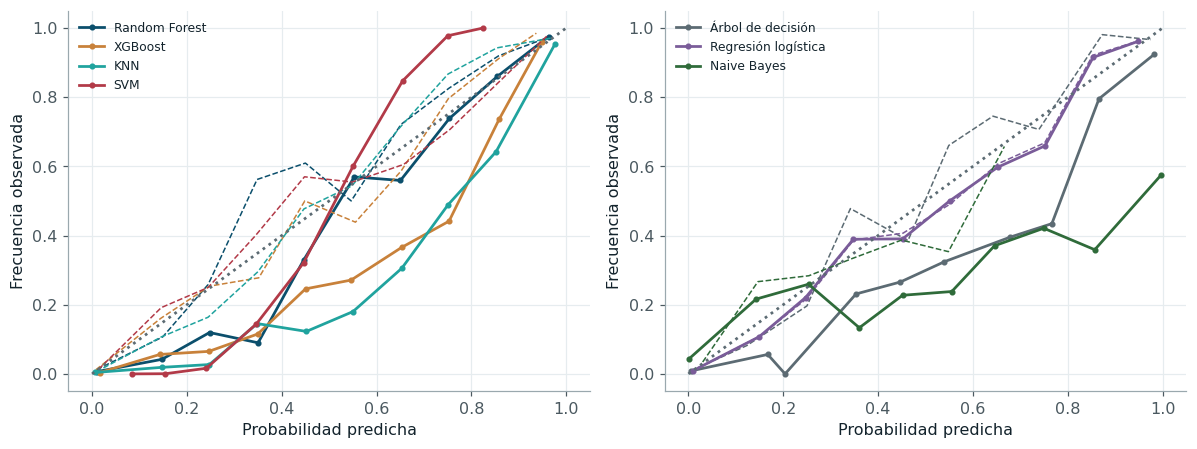

In [9]:
filas = []
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for i, m in enumerate(orden):
    r = fin[m]; s = r["pred_test"]
    oo = oof("clf_calamar", m, r["balanceo"], r["optimizador"])
    iso = Recalibrador("isotonica").fit(oo.pred.values, oo.y.values).transform(s)
    pla = r["pred_test_recalibrado"]
    from sklearn.metrics import brier_score_loss
    filas.append({"Modelo": NOMBRES_MODELO[m], "Brier": brier_score_loss(y, np.clip(s, 0, 1)), "ECE": ece(y, s),
                  "Brier Platt": brier_score_loss(y, pla), "ECE Platt": ece(y, pla),
                  "Brier isotónica": brier_score_loss(y, iso), "ECE isotónica": ece(y, iso),
                  "Recalibrar (decisión en OOF)": "sí" if r["recalibrar_por_oof"] else "no"})
    c = (COLORES + ["#7a5c99", "#2f6b3a"])[i]
    t = diagrama_confiabilidad(y, s); tp = diagrama_confiabilidad(y, pla)
    ax = axs[0] if i < 4 else axs[1]
    ax.plot(t.prob_predicha, t.frec_observada, "-o", ms=3, color=c, label=NOMBRES_MODELO[m])
    ax.plot(tp.prob_predicha, tp.frec_observada, "--", color=c, lw=1)
for ax in axs:
    ax.plot([0, 1], [0, 1], ":", color=NEU); ax.set(xlabel="Probabilidad predicha", ylabel="Frecuencia observada"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
cal = pd.DataFrame(filas)
peor = cal.loc[cal.ECE.idxmax()]
glue("cal_peor", peor.Modelo, display=False); glue("cal_peor_ece", float(peor.ECE), display=False)
glue("cal_peor_ece_platt", float(peor["ECE Platt"]), display=False)

In [10]:
cal.round(4)

,Modelo,Brier,ECE,Brier Platt,ECE Platt,Brier isotónica,ECE isotónica,Recalibrar (decisión en OOF)
0,Random Forest,0.0486,0.0305,0.0462,0.0188,0.0462,0.0166,sí
1,XGBoost,0.0584,0.0575,0.0479,0.0196,0.0476,0.0117,sí
2,KNN,0.0695,0.0756,0.0515,0.0183,0.0514,0.0142,sí
3,SVM,0.0806,0.1747,0.0473,0.0101,0.0481,0.0163,sí
4,Árbol de decisión,0.0762,0.0636,0.0650,0.0282,0.0671,0.0150,sí
5,Regresión logística,0.0642,0.0189,0.0642,0.0193,0.0649,0.0244,no
6,Naive Bayes,0.1938,0.1927,0.1154,0.0167,0.1130,0.0207,sí


La calibración separa a los modelos con más claridad que la discriminación. La SVM produce
puntajes sin calibrar, porque su función de decisión se transforma con una logística fija, y su
error de calibración esperado es alto; lo mismo ocurre con {glue:text}`cal_peor`
(ECE = {glue:text}`cal_peor_ece:.3f`), cuyas probabilidades se concentran en los extremos por el
supuesto de independencia. La recalibración de Platt, ajustada con las predicciones fuera de
muestra del bucle externo y nunca con la prueba, reduce el ECE de {glue:text}`cal_peor` a
{glue:text}`cal_peor_ece_platt:.3f` y el de la SVM por debajo de 0,011, y mejora el Brier de todos
los modelos salvo la regresión logística, que ya estaba bien calibrada por construcción: su
pérdida logarítmica es una regla propia y la decisión tomada en las predicciones fuera de muestra
fue, correctamente, no recalibrarla. La regresión isotónica logra reducciones similares; se
prefirió Platt por tener solo dos parámetros, menos propensos a sobreajustar con la dependencia
temporal de las predicciones. El dashboard usa la versión recalibrada cuando la decisión en las
predicciones fuera de muestra fue favorable.

## Robustez y estabilidad

In [11]:
rob = pd.read_csv(RESULTADOS / "robustez" / "robustez.csv")
sem = rob[rob.tipo == "semilla"]
var_sem = sem.groupby(["modelo", "pliegue"]).pr_auc.std().groupby("modelo").mean()
var_blq = sem.groupby(["modelo", "seed"]).pr_auc.std().groupby("modelo").mean()
ref = mejores.sort_values("pr_auc_mean", ascending=False).iloc[0].modelo
tab_sem = pd.DataFrame({"desviación entre semillas (media por bloque)": var_sem,
                        "desviación entre bloques (media por semilla)": var_blq})
tab_sem.index = [NOMBRES_MODELO["original"] if i == "original" else f"{NOMBRES_MODELO[ref]} (mejor benchmark)" for i in tab_sem.index]
glue("sd_sem_bench", float(var_sem["benchmark"]), display=False); glue("sd_blq_bench", float(var_blq["benchmark"]), display=False)
dif_top = res.sort_values("pr_auc_mean", ascending=False).pr_auc_mean.head(10)
glue("rango_top10", float(dif_top.max() - dif_top.min()), display=False)
tab_sem.round(4)

,desviación entre semillas (media por bloque),desviación entre bloques (media por semilla)
Random Forest (mejor benchmark),0.0058,0.0785
BLGB (modelo original),0.0029,0.0599


Todas las métricas de este capítulo se reportan como media ± desviación estándar sobre los doce
bloques externos y no como valores puntuales. Para el mejor benchmark, la sensibilidad a la
semilla de inicialización (cinco semillas, con los hiperparámetros elegidos en cada bloque) es
pequeña: la desviación media entre semillas dentro de un bloque es de {glue:text}`sd_sem_bench:.4f`,
frente a una desviación entre bloques de {glue:text}`sd_blq_bench:.4f`. La aleatoriedad del
algoritmo pesa, por tanto, mucho menos que la variabilidad hidrológica entre periodos. Al mismo
tiempo, las diez mejores combinaciones de la tabla maestra se separan en apenas
{glue:text}`rango_top10:.4f` de PR-AUC media, una diferencia del mismo orden que la variabilidad
entre semillas y muy inferior a la variabilidad entre bloques. Las diferencias entre los mejores
benchmarks no son, por tanto, mayores que la variabilidad intrínseca de cada uno, y decidir entre
ellos exige las pruebas formales de la sección de comparación estadística.